# Accidents de la route : où et pourquoi faut-il agir ?

**Contexte :** analyse des accidents corporels de la route en France en 2024.
**Objectif :** identifier où et dans quelles conditions se produisent les accidents graves, pour orienter les actions de prévention.
**Source :** fichiers BAAC 2024, data.gouv.fr
**Auteure :** Fatima-Zahra FRINDOU

## 1. Préparation de l'environnement
Import des bibliothèques nécessaires à l'analyse.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

print("pandas version:", pd.__version__)
print("duckdb version:", duckdb.__version__)

pandas version: 3.0.6
duckdb version: 1.5.6


## 2. Chargement des données
Les 4 fichiers décrivent les mêmes accidents sous 4 angles : circonstances (caract), route (lieux), véhicules et usagers. 
Ils sont reliés par la colonne `Num_Acc`.

In [49]:
# Je charge chaque fichier dans un tableau (DataFrame)
caract = pd.read_csv("../data/caract-2024.csv", sep=";")
lieux = pd.read_csv("../data/lieux-2024.csv", sep=";", low_memory=False)
vehicules = pd.read_csv("../data/vehicules-2024.csv", sep=";")
usagers = pd.read_csv("../data/usagers-2024.csv", sep=";")

# J'affiche la taille de chaque tableau : (lignes, colonnes)
print("caract :", caract.shape)
print("lieux :", lieux.shape)
print("vehicules :", vehicules.shape)
print("usagers :", usagers.shape)

caract : (54402, 15)
lieux : (70248, 18)
vehicules : (92678, 11)
usagers : (125187, 16)


## 3. Découverte des données
Premier aperçu de chaque tableau : contenu, colonnes et types de données.

In [50]:
# J'affiche les 5 premières lignes du tableau caract
caract.head()

,Num_Acc,jour,mois,an,hrmn,lum,dep,com,agg,int,atm,col,adr,lat,long
0,202400000001,25,3,2024,07:40,2,70,70285,1,1,5,1,D438,"47,56277000","6,75832000"
1,202400000002,20,3,2024,15:05,1,21,21054,2,3,7,6,HOTEL DIEU (RUE DE L'),"47,02109000","4,83755000"
2,202400000003,22,3,2024,19:30,2,15,15012,1,1,1,6,Allée des Tilleuls,"44,90238400","2,49641800"
3,202400000004,24,3,2024,17:50,1,14,14118,2,3,7,3,128 Rue d'Authie,"49,19166000","-0,39851000"
4,202400000005,25,3,2024,19:35,5,13,13106,1,3,2,5,BEDOULE (CHEMIN DE LA),"43,39000000","5,35000000"


In [51]:
# J'affiche les informations sur le tableau caract
caract.info()

<class 'pandas.DataFrame'>
RangeIndex: 54402 entries, 0 to 54401
Data columns (total 15 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Num_Acc  54402 non-null  int64
 1   jour     54402 non-null  int64
 2   mois     54402 non-null  int64
 3   an       54402 non-null  int64
 4   hrmn     54402 non-null  str  
 5   lum      54402 non-null  int64
 6   dep      54402 non-null  str  
 7   com      54402 non-null  str  
 8   agg      54402 non-null  int64
 9   int      54402 non-null  int64
 10  atm      54402 non-null  int64
 11  col      54402 non-null  int64
 12  adr      52092 non-null  str  
 13  lat      54402 non-null  str  
 14  long     54402 non-null  str  
dtypes: int64(9), str(6)
memory usage: 6.2 MB


In [52]:
# J'affiche les 5 premières lignes du tableau lieux
lieux.head()

,Num_Acc,catr,voie,v1,v2,circ,nbv,vosp,prof,pr,pr1,plan,lartpc,larrout,surf,infra,situ,vma
0,202400000001,3,D438,0,NaN,2,2,0,1,1,260,2,NaN,7,1,0,1,90
1,202400000002,4,HOTEL DIEU (RUE DE L'),0,NaN,2,2,0,1,-1,-1,1,NaN,-1,9,0,1,30
2,202400000002,4,POTERNE (RUE),0,NaN,1,1,0,1,-1,-1,1,NaN,-1,9,0,1,30
3,202400000003,4,TILLEULS (ALLEE DES),0,NaN,2,2,0,1,-1,-1,1,NaN,-1,1,0,3,50
4,202400000004,4,AUTHIE (N° 106 PAIRS -115 IMPAIRS),0,NaN,2,4,0,1,-1,-1,1,NaN,-1,1,9,1,50


In [53]:
# J'affiche les informations sur le tableau lieux
lieux.info()

<class 'pandas.DataFrame'>
RangeIndex: 70248 entries, 0 to 70247
Data columns (total 18 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Num_Acc  70248 non-null  int64
 1   catr     70248 non-null  int64
 2   voie     56917 non-null  str  
 3   v1       70248 non-null  int64
 4   v2       5916 non-null   str  
 5   circ     70248 non-null  int64
 6   nbv      70248 non-null  str  
 7   vosp     70248 non-null  int64
 8   prof     70248 non-null  int64
 9   pr       70248 non-null  str  
 10  pr1      70248 non-null  str  
 11  plan     70248 non-null  int64
 12  lartpc   33 non-null     str  
 13  larrout  70248 non-null  str  
 14  surf     70248 non-null  int64
 15  infra    70248 non-null  int64
 16  situ     70248 non-null  int64
 17  vma      70248 non-null  int64
dtypes: int64(11), str(7)
memory usage: 9.6 MB


In [54]:
# J'affiche les 5 premières lignes du tableau vehicules
vehicules.head()

,Num_Acc,id_vehicule,num_veh,senc,catv,obs,obsm,choc,manv,motor,occutc
0,202400000001,155 781 758,A01,1,7,0,2,1,13,1,NaN
1,202400000001,155 781 759,B01,2,14,0,2,2,21,1,NaN
2,202400000002,155 781 757,A01,1,10,0,1,3,15,1,NaN
3,202400000003,155 781 756,A01,3,3,9,1,1,1,1,NaN
4,202400000004,155 781 754,B01,3,34,0,2,0,0,1,NaN


In [55]:
# J'affiche les informations sur le tableau vehicules
vehicules.info()

<class 'pandas.DataFrame'>
RangeIndex: 92678 entries, 0 to 92677
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Num_Acc      92678 non-null  int64  
 1   id_vehicule  92678 non-null  str    
 2   num_veh      92678 non-null  str    
 3   senc         92678 non-null  int64  
 4   catv         92678 non-null  int64  
 5   obs          92678 non-null  int64  
 6   obsm         92678 non-null  int64  
 7   choc         92678 non-null  int64  
 8   manv         92678 non-null  int64  
 9   motor        92678 non-null  int64  
 10  occutc       949 non-null    float64
dtypes: float64(1), int64(8), str(2)
memory usage: 7.8 MB


In [56]:
# J'affiche les 5 premières lignes du tableau usagers
usagers.head()

,Num_Acc,id_usager,id_vehicule,num_veh,place,catu,grav,sexe,an_nais,trajet,secu1,secu2,secu3,locp,actp,etatp
0,202400000001,203 988 581,155 781 758,A01,1,1,3,1,2003.0,2,1,-1,-1,-1,-1,-1
1,202400000001,203 988 582,155 781 759,B01,1,1,1,1,1997.0,4,1,-1,-1,-1,-1,-1
2,202400000002,203 988 579,155 781 757,A01,10,3,3,2,1927.0,5,0,-1,-1,3,3,1
3,202400000002,203 988 580,155 781 757,A01,1,1,1,1,1987.0,4,1,0,-1,3,3,1
4,202400000003,203 988 574,155 781 756,A01,2,2,4,2,2007.0,5,8,0,-1,-1,-1,-1


In [57]:
# J'affiche les informations sur le tableau usagers
usagers.info()

<class 'pandas.DataFrame'>
RangeIndex: 125187 entries, 0 to 125186
Data columns (total 16 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Num_Acc      125187 non-null  int64  
 1   id_usager    125187 non-null  str    
 2   id_vehicule  125187 non-null  str    
 3   num_veh      125187 non-null  str    
 4   place        125187 non-null  int64  
 5   catu         125187 non-null  int64  
 6   grav         125187 non-null  int64  
 7   sexe         125187 non-null  int64  
 8   an_nais      122608 non-null  float64
 9   trajet       125187 non-null  int64  
 10  secu1        125187 non-null  int64  
 11  secu2        125187 non-null  int64  
 12  secu3        125187 non-null  int64  
 13  locp         125187 non-null  int64  
 14  actp         125187 non-null  str    
 15  etatp        125187 non-null  int64  
dtypes: float64(1), int64(11), str(4)
memory usage: 15.3 MB


In [58]:
usagers["Num_Acc"].head()

0    202400000001
1    202400000001
2    202400000002
3    202400000002
4    202400000003
Name: Num_Acc, dtype: int64

In [59]:
usagers["Num_Acc"].nunique()

54402

**Conclusion de la découverte :**
- ✅ **Problème résolu :** le fichier usagers avait été abîmé par Excel (numéros d'accident tronqués en `2,024E+11`). 
Fichier retéléchargé : la colonne `Num_Acc`, qui relie les 4 tableaux, est maintenant au même format partout (54 402 accidents).
- 🔧 **À corriger :** `lat` et `long` utilisent une virgule décimale (lues comme du texte), et `hrmn` est au format texte.
- ⚠️ **À retenir :** plusieurs colonnes sont des codes (`lum`, `atm`, `grav`…), à traduire avec le dictionnaire des données.
- 🗑️ **À supprimer :** colonnes presque vides (`lartpc`, `v2`, `occutc`).
- 🔍 **À vérifier avant la fusion :** `lieux` compte plus de lignes que d'accidents (70 248 contre 54 402).

## 4. Nettoyage des données
Correction des problèmes repérés lors de la découverte : colonnes inutiles, formats incorrects et lignes en trop.

### 4.1 Suppression des colonnes presque vides

In [60]:
# Je supprime les colonnes presque vides et je réenregistre le résultat
lieux = lieux.drop(columns=["lartpc", "v2"])
vehicules = vehicules.drop(columns=["occutc"])

# Je vérifie le nouveau nombre de colonnes
print("lieux :", lieux.shape)
print("vehicules :", vehicules.shape)

lieux : (70248, 16)
vehicules : (92678, 10)


### 4.2 Conversion des coordonnées GPS en nombres
Remplacement de la virgule par un point, puis conversion du texte en nombre décimal.

In [61]:
# Je remplace la virgule par un point, puis je convertis en nombre décimal
caract["lat"] = caract["lat"].str.replace(",", ".").astype(float)
caract["long"] = caract["long"].str.replace(",", ".").astype(float)

# Je vérifie le nouveau type des deux colonnes
caract[["lat", "long"]].dtypes

lat     float64
long    float64
dtype: object

### 4.3 Création des colonnes heure et date
Extraction de l'heure depuis `hrmn` et assemblage d'une date complète à partir de `jour`, `mois` et `an`.

In [62]:
# Je garde les 2 premiers caractères de hrmn ("07:40" → "07") et je les convertis en nombre
caract["heure"] = caract["hrmn"].str[:2].astype(int)

# J'assemble an, mois et jour en texte "2024-3-25", puis je le convertis en vraie date
caract["date"] = pd.to_datetime(
    caract["an"].astype(str) + "-" + caract["mois"].astype(str) + "-" + caract["jour"].astype(str)
)

# Je vérifie le résultat sur les 5 premières lignes
caract[["hrmn", "heure", "jour", "mois", "an", "date"]].head()

,hrmn,heure,jour,mois,an,date
0,07:40,7,25,3,2024,2024-03-25
1,15:05,15,20,3,2024,2024-03-20
2,19:30,19,22,3,2024,2024-03-22
3,17:50,17,24,3,2024,2024-03-24
4,19:35,19,25,3,2024,2024-03-25


### 4.4 Contrôle des doublons dans lieux
Le tableau lieux compte plus de lignes que d'accidents : vérification du nombre d'accidents concernés avant de décider du traitement.

In [63]:
# Je compte combien de lignes ont un Num_Acc déjà vu plus haut (= lignes en trop)
print("Lignes en trop :", lieux["Num_Acc"].duplicated().sum())

# Je compte combien d'accidents différents sont présents dans lieux
print("Accidents distincts :", lieux["Num_Acc"].nunique())

Lignes en trop : 15846
Accidents distincts : 54402


In [64]:
# Je repère le premier accident qui apparaît plusieurs fois
exemple = lieux[lieux["Num_Acc"].duplicated()]["Num_Acc"].iloc[0]

# J'affiche toutes les lignes de lieux pour cet accident
lieux[lieux["Num_Acc"] == exemple]

,Num_Acc,catr,voie,v1,circ,nbv,vosp,prof,pr,pr1,plan,larrout,surf,infra,situ,vma
1,202400000002,4,HOTEL DIEU (RUE DE L'),0,2,2,0,1,-1,-1,1,-1,9,0,1,30
2,202400000002,4,POTERNE (RUE),0,1,1,0,1,-1,-1,1,-1,9,0,1,30


In [65]:
# Je garde une seule ligne par accident : la première (la route principale)
lieux = lieux.drop_duplicates(subset="Num_Acc", keep="first")

# Je vérifie : le nombre de lignes doit être égal au nombre d'accidents
print("lieux :", lieux.shape)
print("Lignes en trop restantes :", lieux["Num_Acc"].duplicated().sum())

lieux : (54402, 16)
Lignes en trop restantes : 0


### 4.5 Contrôle des valeurs anormales
Repérage des valeurs « non renseigné » (codées -1) et des valeurs incohérentes dans le nombre de voies (`nbv`).

In [66]:
# Je compte le nombre de -1 dans chaque colonne de lieux
(lieux == -1).sum()

Num_Acc        0
catr           0
voie           0
v1         11437
circ        3524
nbv            0
vosp        1280
prof          11
pr             0
pr1            0
plan           8
larrout        0
surf           6
infra        568
situ           5
vma         1567
dtype: int64

In [67]:
# J'affiche chaque valeur de nbv avec son nombre d'apparitions
lieux["nbv"].value_counts()

nbv
2               34321
1                5600
4                4640
3                4336
0                1862
 -1              1809
6                 943
5                 514
8                 221
7                  55
#VALEURMULTI       46
10                 32
9                  12
12                 10
11                  1
Name: count, dtype: int64

In [68]:
# 1. nbv : je convertis en nombre ; ce qui n'est pas convertible (#VALEURMULTI) devient vide
lieux["nbv"] = pd.to_numeric(lieux["nbv"], errors="coerce")

# 2. Je remplace tous les -1 ("non renseigné") par une case vide dans lieux, vehicules et usagers
lieux = lieux.replace(-1, np.nan)
vehicules = vehicules.replace(-1, np.nan)
usagers = usagers.replace(-1, np.nan)

# 3. Dans caract, uniquement sur les colonnes de codes (pas sur lat/long, qui ont de vrais négatifs)
colonnes_codes = ["lum", "agg", "int", "atm", "col"]
caract[colonnes_codes] = caract[colonnes_codes].replace(-1, np.nan)

# Je vérifie : il ne doit plus rester de -1 dans lieux, et nbv doit être un nombre
print("-1 restants dans lieux :", (lieux == -1).sum().sum())
print("Type de nbv :", lieux["nbv"].dtype)

-1 restants dans lieux : 0
Type de nbv : float64


**Conclusion du nettoyage :**
- 🗑️ **Colonnes presque vides supprimées :** `lartpc`, `v2` (lieux) et `occutc` (vehicules).
- 🔧 **Formats corrigés :** `lat` et `long` convertis en nombres décimaux ; colonnes `heure` (0 à 23) et `date` créées à partir de `hrmn`, `jour`, `mois` et `an`.
- 🔍 **Doublons traités :** 15 846 lignes en trop dans lieux, qui correspondent à des accidents à des carrefours (une ligne par route). Seule la route principale a été conservée : lieux compte désormais une ligne par accident (54 402). Les informations sur la seconde route ne sont pas utilisées.
- ❓ **Valeurs « non renseigné » :** les -1 et les valeurs d'erreur (`#VALEURMULTI`) ont été remplacés par des cases vides, pour ne pas fausser les calculs (exemple : 1 567 vitesses maximales non renseignées).
- ⚠️ **Point de vigilance :** 1 862 lieux indiquent 0 voie de circulation. Cette valeur incohérente est conservée, faute de pouvoir la corriger.

## 5. Fusion des tableaux
Assemblage des 4 tableaux en un seul, avec **une ligne par personne impliquée**, car la gravité se mesure au niveau de chaque personne. Chaque usager est relié à son véhicule, puis aux circonstances et au lieu de l'accident.

In [69]:
# 1. J'ajoute à chaque usager les infos de son véhicule (même accident + même véhicule)
df = usagers.merge(vehicules, on=["Num_Acc", "id_vehicule", "num_veh"], how="left")

# 2. J'ajoute les circonstances de l'accident (date, heure, météo, luminosité...)
df = df.merge(caract, on="Num_Acc", how="left")

# 3. J'ajoute les caractéristiques de la route
df = df.merge(lieux, on="Num_Acc", how="left")

# J'affiche la taille du tableau final
print("Tableau final :", df.shape)

Tableau final : (125187, 54)


In [70]:
# Contrôle 1 : le nombre de lignes doit rester égal au nombre d'usagers
print("Lignes :", len(df), "| Usagers au départ :", len(usagers))

# Contrôle 2 : le nombre d'accidents doit rester 54 402
print("Accidents distincts :", df["Num_Acc"].nunique())

# Contrôle 3 : chaque ligne doit avoir trouvé ses infos (0 case vide attendue)
print("Sans circonstances :", df["an"].isna().sum())
print("Sans lieu :", df["catr"].isna().sum())
print("Sans véhicule :", df["catv"].isna().sum())

Lignes : 125187 | Usagers au départ : 125187
Accidents distincts : 54402
Sans circonstances : 0
Sans lieu : 0
Sans véhicule : 1


**Conclusion de la fusion :**
- ✅ Les 4 tableaux sont assemblés en un seul tableau de 125 187 lignes (une par personne impliquée) et 54 colonnes.
- ✅ Contrôles validés : aucune ligne ajoutée ni perdue, les 54 402 accidents sont présents, et chaque personne est reliée à son accident et à son lieu.
- ⚠️ 1 personne n'a pas de catégorie de véhicule (valeur non renseignée dans la source) : impact négligeable.

## 6. Analyse exploratoire
Objectif : comprendre où, quand, qui et dans quelles conditions se produisent les accidents graves.

### 6.1 Création des indicateurs
Traduction de la gravité en libellés, création de l'indicateur « victime grave » (tué ou blessé hospitalisé), calcul de l'âge et des tranches d'âge.

In [71]:
# Je traduis les codes de gravité en libellés lisibles (source : dictionnaire BAAC)
df["gravite"] = df["grav"].map({
    1: "Indemne",
    2: "Tué",
    3: "Blessé hospitalisé",
    4: "Blessé léger"
})

# Je crée l'indicateur clé : Vrai si la personne est tuée ou hospitalisée
df["victime_grave"] = df["grav"].isin([2, 3])

# Je calcule l'âge au moment de l'accident
df["age"] = 2024 - df["an_nais"]

# Je regroupe les âges en tranches
df["tranche_age"] = pd.cut(
    df["age"],
    bins=[-1, 17, 24, 44, 64, 120],
    labels=["0-17 ans", "18-24 ans", "25-44 ans", "45-64 ans", "65 ans et +"]
)

# Je vérifie le résultat
df[["grav", "gravite", "victime_grave", "an_nais", "age", "tranche_age"]].head()

,grav,gravite,victime_grave,an_nais,age,tranche_age
0,3,Blessé hospitalisé,True,2003.0,21.0,18-24 ans
1,1,Indemne,False,1997.0,27.0,25-44 ans
2,3,Blessé hospitalisé,True,1927.0,97.0,65 ans et +
3,1,Indemne,False,1987.0,37.0,25-44 ans
4,4,Blessé léger,False,2007.0,17.0,0-17 ans


### 6.2 Chiffres clés 2024

In [72]:
# Je calcule les indicateurs principaux
nb_accidents = df["Num_Acc"].nunique()
nb_personnes = len(df)
nb_tues = (df["grav"] == 2).sum()
nb_hospitalises = (df["grav"] == 3).sum()
nb_graves = df["victime_grave"].sum()

# Je les affiche
print("Accidents :", nb_accidents)
print("Personnes impliquées :", nb_personnes)
print("Tués :", nb_tues)
print("Blessés hospitalisés :", nb_hospitalises)
print("Victimes graves (tués + hospitalisés) :", nb_graves)
print("Part des victimes graves :", round(nb_graves / nb_personnes * 100, 1), "%")

Accidents : 54402
Personnes impliquées : 125187
Tués : 3432
Blessés hospitalisés : 19126
Victimes graves (tués + hospitalisés) : 22558
Part des victimes graves : 18.0 %


**Chiffres clés 2024 :**
- 54 402 accidents corporels, impliquant 125 187 personnes.
- **3 432 tués** (environ 9 par jour) et **19 126 blessés hospitalisés**, soit **22 558 victimes graves**.
- 18 % des personnes impliquées sont tuées ou hospitalisées.
- ✅ Contrôle qualité : le nombre de tués correspond exactement au bilan officiel de l'ONISR pour 2024 (3 432, métropole et outre-mer).

### 6.3 Quand ? Les victimes graves selon l'heure

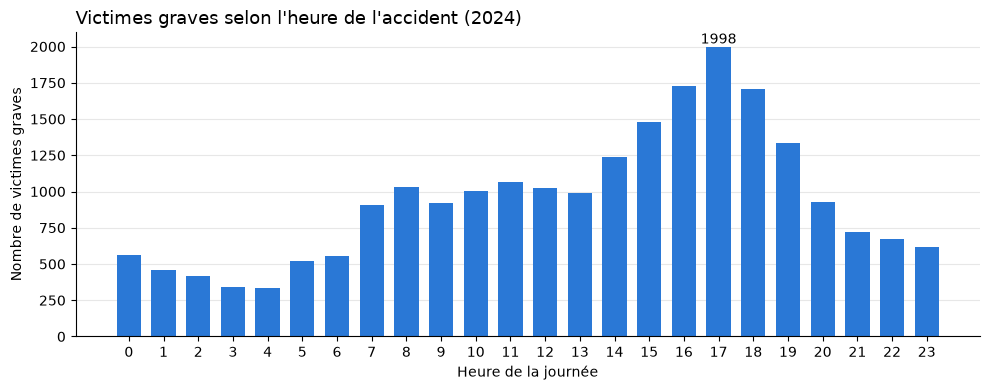

Heure la plus meurtrière : 17 h


In [73]:
# 1. Je garde uniquement les victimes graves, puis je les compte par heure
graves = df[df["victime_grave"]]
par_heure = graves.groupby("heure").size()

# 2. Je dessine un graphique en barres
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(par_heure.index, par_heure.values, color="#2a78d6", width=0.7)

# Titres et axes
ax.set_title("Victimes graves selon l'heure de l'accident (2024)", loc="left", fontsize=13)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Nombre de victimes graves")
ax.set_xticks(range(0, 24))

# Allègement visuel : je retire les bords inutiles et j'ajoute une grille discrète
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# J'affiche la valeur de la barre la plus haute
heure_max = par_heure.idxmax()
ax.annotate(str(par_heure.max()), (heure_max, par_heure.max()), ha="center", va="bottom")

plt.tight_layout()
plt.show()

print("Heure la plus meurtrière :", heure_max, "h")

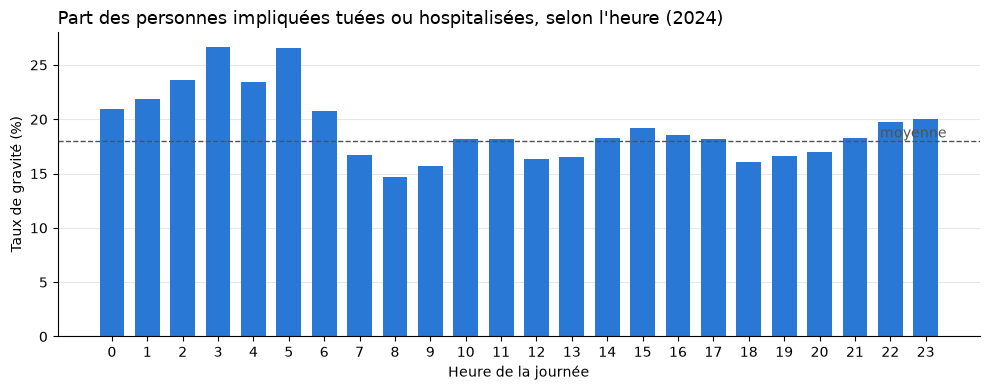

Heure au taux le plus élevé : 3 h → 26.7 %


In [74]:
# Je calcule, pour chaque heure, la part des personnes impliquées qui sont victimes graves (en %)
taux_heure = df.groupby("heure")["victime_grave"].mean() * 100

# Je dessine le graphique
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(taux_heure.index, taux_heure.values, color="#2a78d6", width=0.7)

ax.set_title("Part des personnes impliquées tuées ou hospitalisées, selon l'heure (2024)", loc="left", fontsize=13)
ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Taux de gravité (%)")
ax.set_xticks(range(0, 24))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Je trace la moyenne nationale (18 %) en pointillés, pour comparer
ax.axhline(nb_graves / nb_personnes * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(23.6, nb_graves / nb_personnes * 100, " moyenne", va="bottom", ha="right", color="#52514e")

plt.tight_layout()
plt.show()

print("Heure au taux le plus élevé :", taux_heure.idxmax(), "h →", round(taux_heure.max(), 1), "%")

**Quand ?**
- En nombre, les victimes graves culminent à **17 h** (1 998 victimes), à la sortie du travail, quand le trafic est le plus dense.
- Mais c'est **la nuit** que les accidents sont les plus graves : entre 3 h et 5 h, le taux de gravité atteint 26.7 %, contre 18 % en moyenne.
- 💡 Deux leviers différents : réduire le nombre d'accidents aux heures de pointe, et réduire leur gravité la nuit.
- Hypothèses à vérifier : vitesse, fatigue, alcool et obscurité (la luminosité sera analysée en 6.6).

### 6.4 Qui ? Les victimes graves selon l'âge

             victimes_graves  taux_gravite
tranche_age                               
0-17 ans                2200          19.2
18-24 ans               4328          18.5
25-44 ans               6486          14.8
45-64 ans               5379          18.1
65 ans et +             4164          29.1


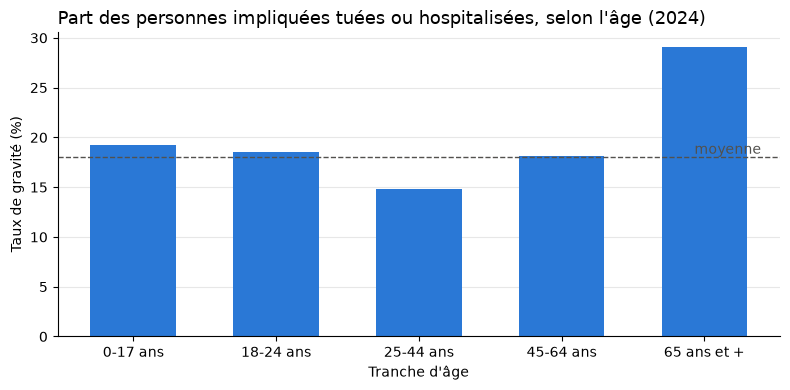

In [75]:
# 1. Pour chaque tranche d'âge : nombre de victimes graves et taux de gravité
par_age = df.groupby("tranche_age", observed=True).agg(
    victimes_graves=("victime_grave", "sum"),
    taux_gravite=("victime_grave", "mean")
)
par_age["taux_gravite"] = (par_age["taux_gravite"] * 100).round(1)
print(par_age)

# 2. Je dessine le taux de gravité par tranche d'âge
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(par_age.index.astype(str), par_age["taux_gravite"], color="#2a78d6", width=0.6)

ax.set_title("Part des personnes impliquées tuées ou hospitalisées, selon l'âge (2024)", loc="left", fontsize=13)
ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Taux de gravité (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Ligne de la moyenne nationale
ax.axhline(nb_graves / nb_personnes * 100, color="#52514e", linestyle="--", linewidth=1)
ax.text(4.4, nb_graves / nb_personnes * 100, " moyenne", va="bottom", ha="right", color="#52514e")

plt.tight_layout()
plt.show()

**Qui ?**
- **Les seniors (65 ans et +)** ont le taux de gravité le plus élevé : 29,1 % des seniors impliqués sont tués ou hospitalisés, contre 18 % en moyenne. Leur plus grande fragilité physique aggrave les conséquences du choc.
- **Les 18-24 ans** sont les plus exposés : 4 328 victimes graves sur seulement 7 années d'âge, soit environ 620 par année d'âge, près du double des 25-44 ans.
- 💡 Deux publics prioritaires, deux leviers : protéger les seniors (aménagements, piétons), et prévenir les comportements à risque chez les jeunes.

### 6.5 Où ? Agglomération et type de route

In [76]:
# Je traduis le code agg en libellés (dictionnaire BAAC)
df["agglo"] = df["agg"].map({1: "Hors agglomération", 2: "En agglomération"})

# Nombre de victimes graves et taux de gravité, en ville et hors ville
par_agglo = df.groupby("agglo").agg(
    victimes_graves=("victime_grave", "sum"),
    taux_gravite=("victime_grave", "mean")
)
par_agglo["taux_gravite"] = (par_agglo["taux_gravite"] * 100).round(1)
par_agglo

,victimes_graves,taux_gravite
agglo,,
En agglomération,9892,13.1
Hors agglomération,12666,25.6


                            victimes_graves  taux_gravite
type_route                                               
Autoroute                              1503          10.5
Voie communale                         6177          12.4
Route de métropole urbaine              604          16.7
Route nationale                        1745          19.3
Parking                                 184          20.3
Hors réseau public                       28          25.5
Route départementale                  12191          26.1
Autre                                   126          27.3


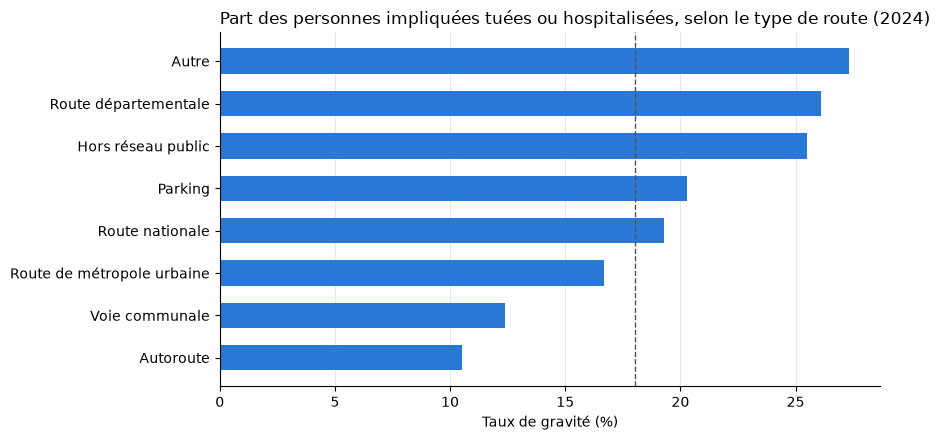

In [77]:
# Je traduis le code catr en libellés (dictionnaire BAAC)
df["type_route"] = df["catr"].map({
    1: "Autoroute",
    2: "Route nationale",
    3: "Route départementale",
    4: "Voie communale",
    5: "Hors réseau public",
    6: "Parking",
    7: "Route de métropole urbaine",
    9: "Autre"
})

# Nombre et taux par type de route, triés du taux le plus faible au plus élevé
par_route = df.groupby("type_route").agg(
    victimes_graves=("victime_grave", "sum"),
    taux_gravite=("victime_grave", "mean")
)
par_route["taux_gravite"] = (par_route["taux_gravite"] * 100).round(1)
par_route = par_route.sort_values("taux_gravite")
print(par_route)

# Barres horizontales : plus lisibles quand les noms de catégories sont longs
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(par_route.index, par_route["taux_gravite"], color="#2a78d6", height=0.6)

ax.set_title("Part des personnes impliquées tuées ou hospitalisées, selon le type de route (2024)", loc="left", fontsize=12)
ax.set_xlabel("Taux de gravité (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Ligne de la moyenne nationale
ax.axvline(nb_graves / nb_personnes * 100, color="#52514e", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

**Où ?**
- **Hors agglomération**, le taux de gravité est presque le double de celui des villes (25,6 % contre 13,1 %), et on y compte plus de victimes graves (12 666 contre 9 892).
- **Les routes départementales sont la priorité n°1** : 12 191 victimes graves, soit 54 % du total national, avec un taux de gravité de 26,1 %.
- **Les autoroutes sont les plus sûres** (10,5 %), grâce à la séparation des sens de circulation et à l'absence de croisements.
- ⚠️ Les catégories « Autre » et « Hors réseau public » ont des taux élevés, mais sur trop peu de cas (moins de 130 victimes graves) pour être interprétées.
- 💡 Levier principal : la vitesse et l'aménagement des routes départementales hors agglomération.

### 6.6 Dans quelles conditions ? Luminosité et météo

                            victimes_graves  taux_gravite
luminosite                                               
Nuit avec éclairage public             2512          12.9
Plein jour                            14144          17.3
Crépuscule ou aube                     1651          20.2
Nuit, éclairage non allumé              310          21.7
Nuit sans éclairage public             3941          27.5


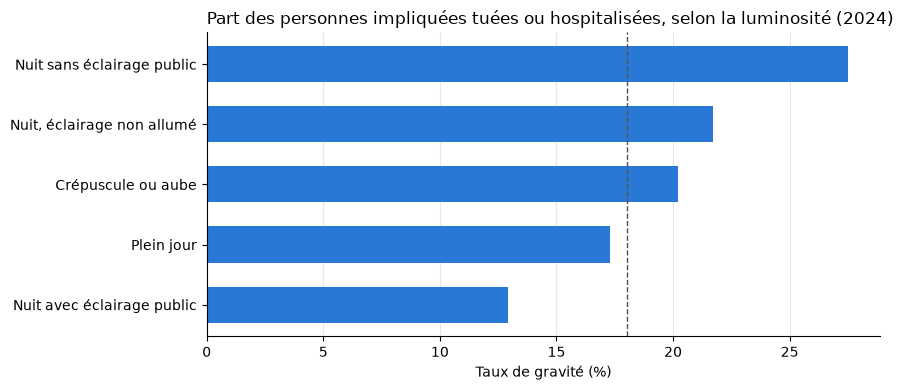

In [78]:
# Je traduis le code lum en libellés (dictionnaire BAAC)
df["luminosite"] = df["lum"].map({
    1: "Plein jour",
    2: "Crépuscule ou aube",
    3: "Nuit sans éclairage public",
    4: "Nuit, éclairage non allumé",
    5: "Nuit avec éclairage public"
})

# Nombre et taux par luminosité, triés par taux
par_lum = df.groupby("luminosite").agg(
    victimes_graves=("victime_grave", "sum"),
    taux_gravite=("victime_grave", "mean")
)
par_lum["taux_gravite"] = (par_lum["taux_gravite"] * 100).round(1)
par_lum = par_lum.sort_values("taux_gravite")
print(par_lum)

# Barres horizontales
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(par_lum.index, par_lum["taux_gravite"], color="#2a78d6", height=0.6)

ax.set_title("Part des personnes impliquées tuées ou hospitalisées, selon la luminosité (2024)", loc="left", fontsize=12)
ax.set_xlabel("Taux de gravité (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.axvline(nb_graves / nb_personnes * 100, color="#52514e", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

In [79]:
# Je traduis le code atm en libellés (dictionnaire BAAC)
df["meteo"] = df["atm"].map({
    1: "Normale",
    2: "Pluie légère",
    3: "Pluie forte",
    4: "Neige ou grêle",
    5: "Brouillard ou fumée",
    6: "Vent fort ou tempête",
    7: "Temps éblouissant",
    8: "Temps couvert",
    9: "Autre"
})

# Nombre et taux par météo, triés par taux
par_meteo = df.groupby("meteo").agg(
    victimes_graves=("victime_grave", "sum"),
    taux_gravite=("victime_grave", "mean")
)
par_meteo["taux_gravite"] = (par_meteo["taux_gravite"] * 100).round(1)
par_meteo.sort_values("taux_gravite", ascending=False)

,victimes_graves,taux_gravite
meteo,,
Vent fort ou tempête,112,30.8
Temps éblouissant,507,27.8
Brouillard ou fumée,363,27.8
Autre,141,26.7
Normale,17504,18.2
Pluie forte,621,18.2
Temps couvert,923,17.1
Neige ou grêle,102,16.6
Pluie légère,2285,14.8


**Dans quelles conditions ?**
- **Nuit sans éclairage public : taux de gravité le plus élevé (27,5 %).** Mais la nuit avec éclairage public a le taux le plus bas (12,9 %), plus bas encore qu'en plein jour. Ce n'est donc pas la nuit en elle-même qui aggrave les accidents, mais surtout le **lieu** : les routes non éclairées sont des routes hors agglomération, où l'on roule plus vite.
- **Le mauvais temps n'est pas la cause principale :** 78 % des victimes graves surviennent par temps normal. Par pluie légère, le taux est même inférieur à la moyenne (14,8 %), car les conducteurs ralentissent.
- **La mauvaise visibilité aggrave les accidents :** brouillard et temps éblouissant atteignent 27,8 %.
- ⚠️ Vent fort et neige : trop peu de cas pour conclure.
- 💡 La météo n'est pas le levier principal. L'enjeu reste la vitesse sur les routes hors agglomération.

### 6.7 Synthèse : où et pourquoi faut-il agir ?

**Messages clés**
1. **Le danger se concentre hors des villes.** Les routes départementales regroupent 54 % des victimes graves, avec un taux de gravité de 26,1 %. Hors agglomération, un accident est presque deux fois plus souvent grave qu'en ville (25,6 % contre 13,1 %).
2. **La vitesse semble être le facteur commun.** Les situations les plus graves (routes de campagne, nuit sans éclairage, nuit profonde) correspondent à des routes où l'on roule vite. À l'inverse, la ville éclairée et la pluie légère, où l'on roule moins vite, présentent les taux les plus bas.
3. **Deux publics sont prioritaires.** Les 18-24 ans sont les plus exposés (environ 620 victimes graves par année d'âge), et les 65 ans et plus sont les plus vulnérables (29,1 % des seniors impliqués sont tués ou hospitalisés).
4. **Deux moments à cibler.** 17 h concentre le plus de victimes graves (trafic dense), et la nuit (vers 3 h) les accidents les plus graves (26,7 %).

**Recommandations**
- Concentrer les contrôles de vitesse et les aménagements (ronds-points, glissières, éclairage aux points dangereux) sur les routes départementales hors agglomération.
- Mener des campagnes de prévention ciblées sur les 18-24 ans, en particulier sur les trajets de nuit.
- Sécuriser les déplacements des seniors, notamment comme piétons.

**Limites de l'analyse**
- Les données ne disent pas *pourquoi* un accident a lieu (vitesse réelle, alcool, fatigue) : ces causes restent des hypothèses.
- Faute de données sur le trafic, on ne peut pas calculer un risque « par kilomètre parcouru ».
- L'analyse porte sur une seule année (2024) : une comparaison sur plusieurs années confirmerait ces tendances.

## 7. Questions métier en SQL (DuckDB)
Interrogation du tableau final en SQL, comme sur une base de données d'entreprise.

### 7.1 Départements prioritaires

In [84]:
requete = """
SELECT
    dep AS departement,
    COUNT(DISTINCT Num_Acc) AS accidents,
    SUM(CASE WHEN victime_grave THEN 1 ELSE 0 END)::INTEGER AS victimes_graves,
    ROUND(AVG(CASE WHEN victime_grave THEN 1 ELSE 0 END) * 100, 1) AS taux_gravite
FROM df
GROUP BY dep
ORDER BY victimes_graves DESC
LIMIT 10
"""

duckdb.sql(requete).df()

,departement,accidents,victimes_graves,taux_gravite
0,13,2120,842,15.6
1,83,866,551,27.6
2,59,1023,517,22.0
3,33,1202,476,16.0
4,69,1627,467,12.2
5,34,798,452,24.1
6,75,4191,433,4.7
7,62,668,431,28.7
8,77,1068,415,16.0
9,38,650,394,27.0


**Départements prioritaires :**
- Le classement dépend de l'indicateur choisi : **Paris** compte le plus d'accidents (4 191), mais le taux de gravité le plus bas (4,7 %), car on y roule lentement.
- Les départements à dominante rurale ou montagneuse (**Var, Pas-de-Calais, Isère**) ont des taux de gravité proches de 28 %, soit 6 fois celui de Paris.
- Les **Bouches-du-Rhône** concentrent le plus de victimes graves (842), avec un taux moyen : c'est un enjeu de volume de trafic.
- 💡 Les actions doivent être différenciées : réduire la vitesse sur les routes rurales des départements à fort taux, et réduire le nombre d'accidents dans les départements à fort trafic.

### 7.2 Usagers les plus vulnérables
Regroupement des usagers par mode de déplacement. Les piétons sont identifiés à part, car ils sont rattachés au véhicule qui les a percutés.

In [85]:
requete = """
SELECT
    CASE
        WHEN catu = 3 THEN 'Piéton'
        WHEN catv IN (1, 80) THEN 'Vélo'
        WHEN catv IN (50, 60) THEN 'Trottinette / EDP'
        WHEN catv IN (2, 30, 31, 32, 33, 34, 41, 42, 43) THEN 'Deux-roues motorisé'
        WHEN catv = 7 THEN 'Voiture'
        WHEN catv = 10 THEN 'Utilitaire'
        WHEN catv IN (13, 14, 15, 16, 17) THEN 'Poids lourd'
        ELSE 'Autre'
    END AS type_usager,
    COUNT(*) AS personnes,
    SUM(CASE WHEN victime_grave THEN 1 ELSE 0 END)::INTEGER AS victimes_graves,
    ROUND(AVG(CASE WHEN victime_grave THEN 1 ELSE 0 END) * 100, 1) AS taux_gravite
FROM df
GROUP BY type_usager
ORDER BY taux_gravite DESC
"""

duckdb.sql(requete).df()

,type_usager,personnes,victimes_graves,taux_gravite
0,Deux-roues motorisé,19519,6883,35.3
1,Piéton,9401,3089,32.9
2,Vélo,5894,1608,27.3
3,Trottinette / EDP,3295,613,18.6
4,Voiture,71778,9003,12.5
5,Autre,4050,487,12.0
6,Utilitaire,8609,703,8.2
7,Poids lourd,2641,172,6.5


**Usagers les plus vulnérables :**
- Les usagers sans carrosserie sont les plus touchés : **deux-roues motorisés (35,3 %), piétons (32,9 %) et cyclistes (27,3 %)**, contre 12,5 % pour les automobilistes.
- Ils représentent **30 % des personnes impliquées, mais 54 % des victimes graves**.
- Les deux-roues motorisés comptent à eux seuls 6 883 victimes graves, soit près d'une victime grave sur trois.
- 💡 La protection des usagers vulnérables (équipements des motards, aménagements piétons et cyclables) est un levier majeur.

## 8. Export pour Power BI
Création d'un fichier propre, avec uniquement les colonnes utiles et des libellés lisibles, enregistré dans `data/clean`.

In [86]:
# 1. J'ajoute le type d'usager dans df, en réutilisant la logique de la requête SQL 7.2
df = duckdb.sql("""
SELECT *,
    CASE
        WHEN catu = 3 THEN 'Piéton'
        WHEN catv IN (1, 80) THEN 'Vélo'
        WHEN catv IN (50, 60) THEN 'Trottinette / EDP'
        WHEN catv IN (2, 30, 31, 32, 33, 34, 41, 42, 43) THEN 'Deux-roues motorisé'
        WHEN catv = 7 THEN 'Voiture'
        WHEN catv = 10 THEN 'Utilitaire'
        WHEN catv IN (13, 14, 15, 16, 17) THEN 'Poids lourd'
        ELSE 'Autre'
    END AS type_usager
FROM df
""").df()

# 2. J'ajoute le jour de la semaine en français
jours = {0: "Lundi", 1: "Mardi", 2: "Mercredi", 3: "Jeudi", 4: "Vendredi", 5: "Samedi", 6: "Dimanche"}
df["jour_semaine"] = df["date"].dt.dayofweek.map(jours)

# 3. Je traduis le sexe
df["sexe_libelle"] = df["sexe"].map({1: "Homme", 2: "Femme"})

# 4. Je convertis victime_grave en 1/0 : plus pratique pour faire des sommes dans Power BI
df["victime_grave"] = df["victime_grave"].astype(int)

df[["type_usager", "date", "jour_semaine", "sexe_libelle", "victime_grave"]].head()

,type_usager,date,jour_semaine,sexe_libelle,victime_grave
0,Voiture,2024-12-07,Samedi,Homme,1
1,Utilitaire,2024-12-07,Samedi,Homme,0
2,Poids lourd,2024-10-31,Jeudi,Homme,0
3,Piéton,2024-10-31,Jeudi,Homme,1
4,Voiture,2024-09-25,Mercredi,Homme,0


In [87]:
import os

# 1. Je choisis les colonnes utiles et je leur donne des noms clairs
colonnes = {
    "Num_Acc": "id_accident",
    "id_usager": "id_usager",
    "date": "date",
    "mois": "mois",
    "jour_semaine": "jour_semaine",
    "heure": "heure",
    "dep": "departement",
    "agglo": "agglomeration",
    "type_route": "type_route",
    "vma": "vitesse_max",
    "luminosite": "luminosite",
    "meteo": "meteo",
    "lat": "latitude",
    "long": "longitude",
    "type_usager": "type_usager",
    "sexe_libelle": "sexe",
    "age": "age",
    "tranche_age": "tranche_age",
    "gravite": "gravite",
    "victime_grave": "victime_grave"
}
df_export = df[list(colonnes.keys())].rename(columns=colonnes)

# 2. Je crée le dossier data/clean s'il n'existe pas encore
os.makedirs("../data/clean", exist_ok=True)

# 3. J'enregistre le fichier au format CSV français
df_export.to_csv(
    "../data/clean/accidents_2024_clean.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

# 4. Je vérifie en relisant le fichier enregistré
verif = pd.read_csv("../data/clean/accidents_2024_clean.csv", sep=";", decimal=",")
print("Fichier exporté :", verif.shape)

Fichier exporté : (125187, 20)


✅ Fichier `data/clean/accidents_2024_clean.csv` créé : 125 187 lignes (une par personne impliquée) et 20 colonnes aux noms explicites, avec des libellés lisibles. Il est prêt à être importé dans Power BI sans nettoyage supplémentaire.